In [1]:
import os
from pathlib import Path

MODEL_CACHE = Path("/project/6094302/Zak_thesis_dir/ow-test/model-cache")

MODEL_CACHE.mkdir(parents=True, exist_ok=True)

os.environ["HF_HOME"] = str(MODEL_CACHE)

print("Hugging Face cache:", MODEL_CACHE)
print("Directory exists:", MODEL_CACHE.exists())

Hugging Face cache: /project/6094302/Zak_thesis_dir/ow-test/model-cache
Directory exists: True


In [2]:
import shutil

total, used, free = shutil.disk_usage(MODEL_CACHE)

print(f"Total storage: {total / 1024**3:.1f} GB")
print(f"Used storage: {used / 1024**3:.1f} GB")
print(f"Free storage: {free / 1024**3:.1f} GB")

Total storage: 931.3 GB
Used storage: 36.4 GB
Free storage: 894.9 GB


In [4]:
!diskusage_report

                            Description                Space         # of files
                  /home (user zkhan101)      8820MiB/  50GiB          74K/ 500K
               /scratch (user zkhan101)         0  B/1024GiB           1 /1000K
         /project (project def-asilian)        36GiB/ 931GiB         220K/ 500K
--
On some clusters, a break down per user may be available by adding the option '--per_user'.


In [5]:
from huggingface_hub import snapshot_download

MODEL_ID = "Qwen/Qwen-Image-2.1"

model_path = snapshot_download(
    repo_id=MODEL_ID,
    cache_dir=str(MODEL_CACHE),
)

print("Model downloaded to:", model_path)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 28 files:   0%|          | 0/28 [00:00<?, ?it/s]

Model downloaded to: /project/6094302/Zak_thesis_dir/ow-test/model-cache/models--Qwen--Qwen-Image-2.1/snapshots/d26bb61231c349cf6b7896fa83353113880e1ba3


In [6]:
import torch
from diffusers import QwenImage21Pipeline

pipe = QwenImage21Pipeline.from_pretrained(
    model_path,
    torch_dtype=torch.bfloat16,
)

pipe = pipe.to("cuda")

print("Qwen-Image-2.1 loaded successfully!")

free, total = torch.cuda.mem_get_info()
print(f"GPU memory used: {(total - free) / 1024**3:.1f} GB")
print(f"GPU memory free: {free / 1024**3:.1f} GB")

/project/6094302/Zak_thesis_dir/ow-test/.venv/lib/python3.11/site-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/750 [00:00<?, ?it/s]

Qwen-Image-2.1 loaded successfully!
GPU memory used: 30.9 GB
GPU memory free: 48.3 GB


true_cfg_scale is passed as 4.0, but classifier-free guidance is not enabled since no negative_prompt is provided.


  0%|          | 0/30 [00:00<?, ?it/s]

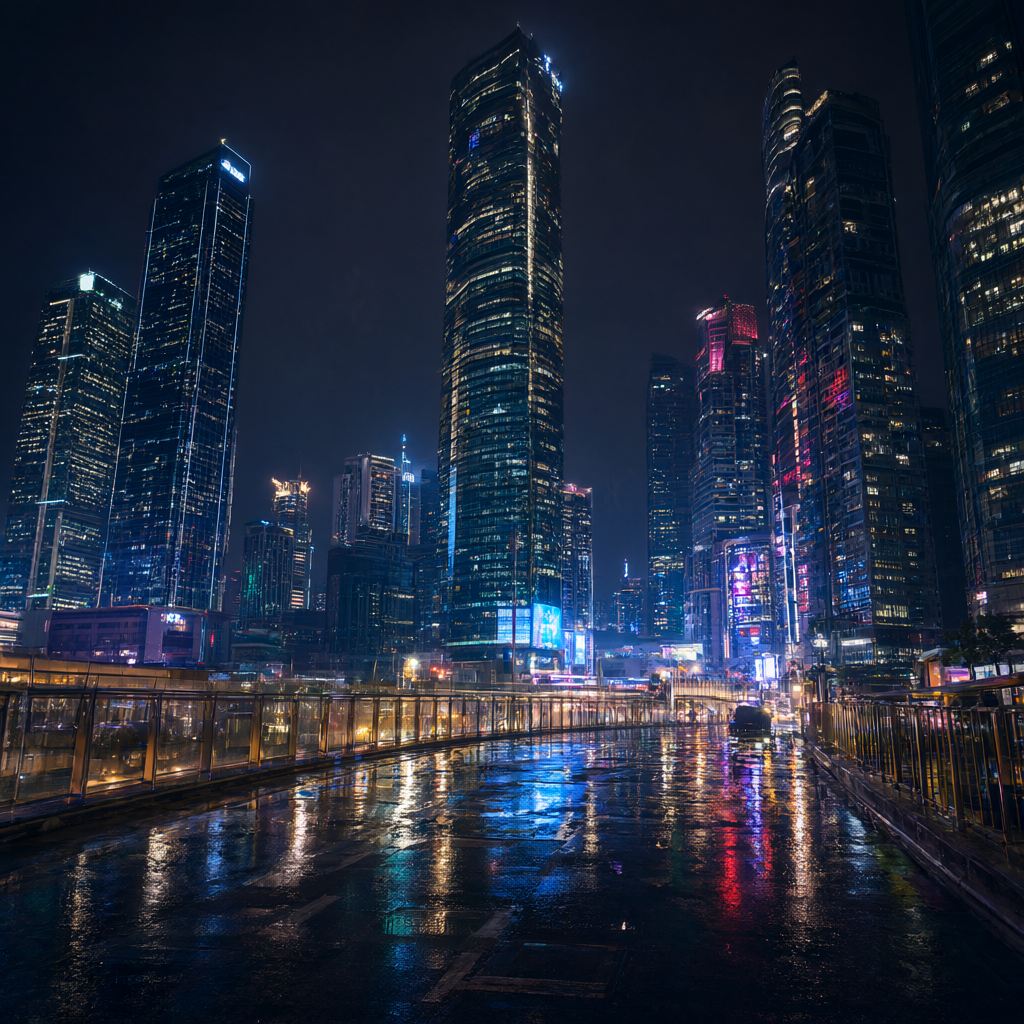

In [7]:
import torch
from IPython.display import display

prompt = (
    "A cinematic photograph of a futuristic city at night, "
    "towering skyscrapers illuminated by neon lights, "
    "rain-soaked streets with reflections, highly detailed, "
    "realistic lighting, 35mm photography"
)

with torch.inference_mode():
    result = pipe(
        prompt=prompt,
        width=1024,
        height=1024,
        num_inference_steps=30,
        true_cfg_scale=4.0,
        generator=torch.Generator(device="cuda").manual_seed(42),
    )

image = result.images[0]
display(image)